In [1]:
# 1. Verify GPU availability
!nvidia-smi

Sun Nov 15 09:33:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Clone or pull latest repository
import os
![ -d "SE374.R11-Group11" ] && (cd SE374.R11-Group11 && git pull) || git clone https://github.com/EmmYeuuKhoaaHocc/SE374.R11-Group11.git
%cd /content/SE374.R11-Group11/apps/worker/training
!pwd

Cloning into 'SE374.R11-Group11'...
remote: Enumerating objects: 205, done.
remote: Total 205 (delta 0), reused 0 (delta 0), pack-reused 205 (from 1)
Receiving objects: 100% (205/205), 53.31 MiB | 17.88 MiB/s, done.
Resolving deltas: 100% (74/74), done.
Updating files: 100% (70/70), done.
/content/SE374.R11-Group11/apps/worker/training
/content/SE374.R11-Group11/apps/worker/training


In [3]:
# 3. Install lightweight inference requirements
!pip install -q nibabel scipy scikit-learn tqdm matplotlib ipywidgets pandas

In [12]:
# 4. Run Sequential Inference on all samples in data/ folder
!python inference.py

Loaded checkpoint successfully from: /content/SE374.R11-Group11/apps/worker/weights/unet3d_final_fp32.pth (device: cuda)
Discovered 4 valid cases in '/content/SE374.R11-Group11/apps/worker/training/data' to process sequentially:
  • BraTS20_Validation_001
  • BraTS20_Validation_002
  • BraTS20_Validation_003
  • BraTS20_Validation_004

[1/4] Running inference for case: BraTS20_Validation_001...
[1/4] Saved segmentation mask to: /content/SE374.R11-Group11/apps/worker/training/predict_example/BraTS20_Validation_001_seg.nii.gz

[2/4] Running inference for case: BraTS20_Validation_002...
[2/4] Saved segmentation mask to: /content/SE374.R11-Group11/apps/worker/training/predict_example/BraTS20_Validation_002_seg.nii.gz

[3/4] Running inference for case: BraTS20_Validation_003...
[3/4] Saved segmentation mask to: /content/SE374.R11-Group11/apps/worker/training/predict_example/BraTS20_Validation_003_seg.nii.gz

[4/4] Running inference for case: BraTS20_Validation_004...
[4/4] Saved segmentatio

In [7]:
# 5. Inspect generated segmentation volumes
!ls -lh predict_example/

total 452K
-rw-r--r-- 1 root root 122K Nov 15 09:34 BraTS20_Validation_001_seg.nii.gz
-rw-r--r-- 1 root root  92K Nov 15 09:34 BraTS20_Validation_002_seg.nii.gz
-rw-r--r-- 1 root root  96K Nov 15 09:34 BraTS20_Validation_003_seg.nii.gz
-rw-r--r-- 1 root root 127K Nov 15 09:34 BraTS20_Validation_004_seg.nii.gz
-rw-r--r-- 1 root root  11K Nov 15 09:33 visualize_results.ipynb


Found 4 segmentation files: ['predict_example/BraTS20_Validation_001_seg.nii.gz', 'predict_example/BraTS20_Validation_002_seg.nii.gz', 'predict_example/BraTS20_Validation_003_seg.nii.gz', 'predict_example/BraTS20_Validation_004_seg.nii.gz']


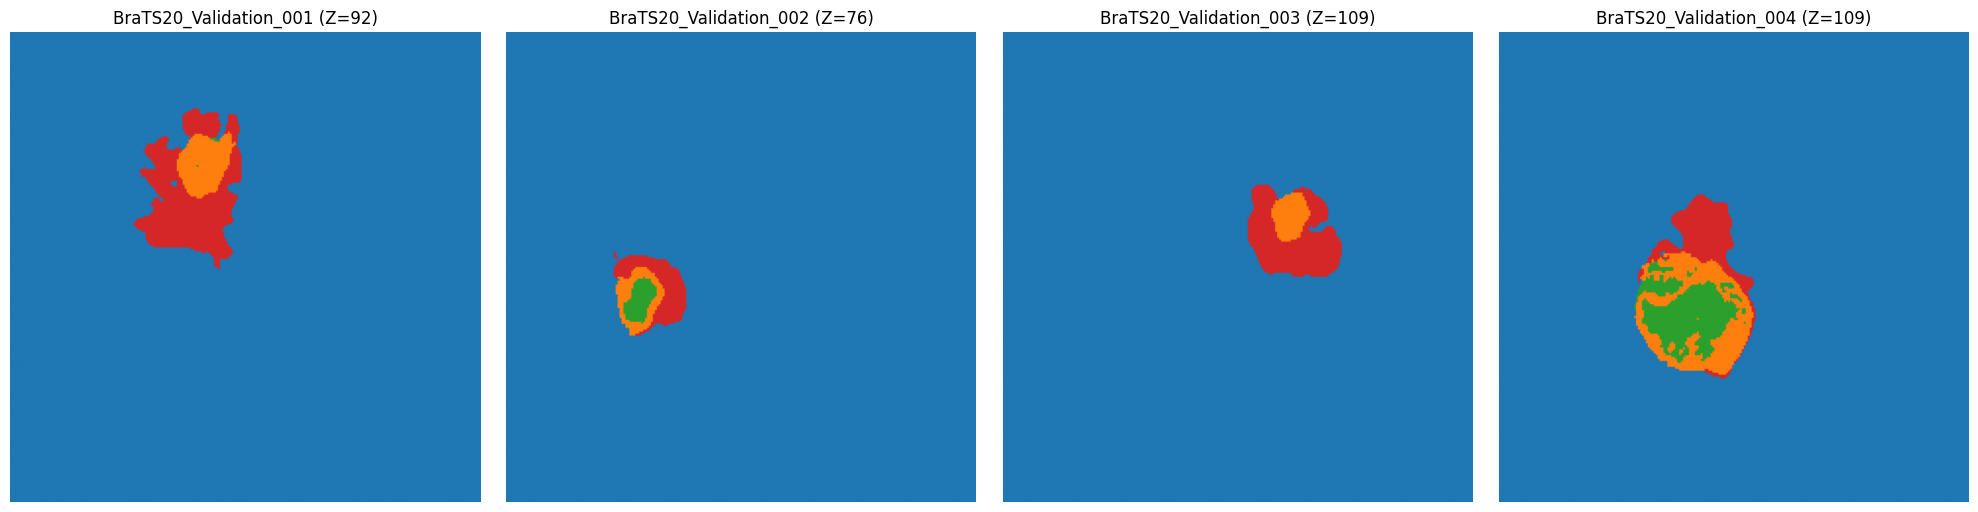

In [10]:
# 6. Quick inline visual check on generated masks
import glob, nibabel as nib, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

seg_files = sorted(glob.glob("predict_example/*_seg.nii.gz"))
print(f"Found {len(seg_files)} segmentation files: {seg_files}")

if seg_files:
    fig, axes = plt.subplots(1, len(seg_files), figsize=(5 * len(seg_files), 5))
    if len(seg_files) == 1: axes = [axes]

    for ax, p in zip(axes, seg_files):
        seg = nib.load(p).get_fdata().astype(np.uint8)
        mid = seg.shape[2] // 2
        # find axial slice with max tumor voxels
        slice_idx = int(np.argmax((seg > 0).sum(axis=(0, 1)))) if (seg > 0).any() else mid
        ax.imshow(np.rot90(seg[:, :, slice_idx]), cmap="tab10", vmin=0, vmax=9)
        cid = Path(p).name.replace("_seg.nii.gz", "")
        ax.set_title(f"{cid} (Z={slice_idx})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()